In [1]:
import pandas as pd
import numpy as np

data_raw = pd.read_csv('results-survey868773.csv')
data_analyze = data_raw.copy()
data_analyze.head(20)

,id,submitdate,lastpage,startlanguage,seed,startdate,datestamp,Video,GROUP,debug,...,groupTime59,TASK3CTime,groupTime60,TASK4CTime,groupTime63,PEATime,groupTime51,AGETime,GENDERTime,EDUTime
0,5,2026-04-29 19:43:37,14,de,1122568344,2026-04-29 19:42:50,2026-04-29 19:43:37,NaN,0,NaN,...,NaN,NaN,NaN,NaN,6.20,NaN,15.37,NaN,NaN,NaN
1,7,2026-04-29 20:06:42,14,de,486316902,2026-04-29 19:55:43,2026-04-29 20:06:42,NaN,1,NaN,...,163.65,NaN,80.27,NaN,36.08,NaN,20.39,NaN,NaN,NaN
2,11,2026-04-30 08:54:30,14,de,843403865,2026-04-30 08:48:16,2026-04-30 08:54:30,NaN,0,NaN,...,NaN,NaN,NaN,NaN,25.49,NaN,15.22,NaN,NaN,NaN
3,12,2026-04-30 09:58:44,14,de,186204985,2026-04-30 09:52:31,2026-04-30 09:58:44,NaN,0,NaN,...,NaN,NaN,NaN,NaN,20.32,NaN,22.56,NaN,NaN,NaN
4,13,2026-04-30 10:07:09,14,de,1227962742,2026-04-30 10:00:36,2026-04-30 10:07:09,NaN,0,NaN,...,NaN,NaN,NaN,NaN,19.71,NaN,15.36,NaN,NaN,NaN
5,14,2026-04-30 10:26:33,14,de,1440477977,2026-04-30 10:17:59,2026-04-30 10:26:33,NaN,0,NaN,...,NaN,NaN,NaN,NaN,70.53,NaN,24.71,NaN,NaN,NaN
6,15,2026-04-30 11:19:54,14,de,153652116,2026-04-30 11:14:01,2026-04-30 11:19:54,NaN,0,NaN,...,NaN,NaN,NaN,NaN,36.65,NaN,16.25,NaN,NaN,NaN
7,16,2026-04-30 11:48:55,14,de,807857037,2026-04-30 11:42:15,2026-04-30 11:48:55,NaN,0,NaN,...,NaN,NaN,NaN,NaN,24.72,NaN,14.17,NaN,NaN,NaN
8,17,2026-04-30 15:40:29,14,de,244101714,2026-04-30 15:35:43,2026-04-30 15:40:29,NaN,1,NaN,...,8.08,NaN,11.39,NaN,11.98,NaN,13.76,NaN,NaN,NaN
9,19,2026-05-01 13:32:43,14,de,1549321472,2026-05-01 13:27:57,2026-05-01 13:32:43,NaN,1,NaN,...,28.01,NaN,53.12,NaN,13.55,NaN,14.58,NaN,NaN,NaN


In [2]:
# Attention checks

data_analyze["mc_1_correct"] = np.where(data_analyze["MP1"] == "MP1C", 1, 0)
data_analyze["mc_2_correct"] = np.where(data_analyze["MP2"] == "MP2C", 1, 0)
data_analyze["mc_3_correct"] = np.where(data_analyze["MP3"] == "MP3C", 1, 0)
data_analyze["mc_total"] = data_analyze["mc_1_correct"] + data_analyze["mc_2_correct"] + data_analyze["mc_3_correct"]

# Drop individuals with more than 2 wrong answers
data_analyze = data_analyze[data_analyze["mc_total"] >= 2]
print(data_analyze.shape[0])

# GROUP 0 = Treatment (TASK*T), 1 = Control (TASK*C)
data_analyze["GROUP2"] = np.where(data_analyze["GROUP"] == 0, "Treatment", "Control")

52


In [3]:
# Put tasks in single columns
for i in range(1, 5):
    data_analyze[f'TASK{i}'] = data_analyze[f'TASK{i}T'].combine_first(data_analyze[f'TASK{i}C'])

sub = data_analyze[['TASK1', 'TASK2', 'TASK3', 'TASK4']].astype(str)

# How many times did each individual select an energy-efficient model
data_analyze['MIN_count'] = sub.apply(lambda c: c.str.contains('MIN', na=False)).sum(axis=1)

# How many times did each individual select a performance-optimized model
data_analyze['PRO_count'] = sub.apply(lambda c: c.str.contains('PRO', na=False)).sum(axis=1)

# Count of answered tasks per respondent (non-null)
n_answered = data_analyze[['TASK1', 'TASK2', 'TASK3', 'TASK4']].notna().sum(axis=1)

data_analyze['MIN_share'] = data_analyze['MIN_count'] / n_answered
data_analyze['PRO_share'] = data_analyze['PRO_count'] / n_answered

data_analyze[['TASK1', 'TASK2', 'TASK3', 'TASK4', 'MIN_count', 'PRO_count', 'MIN_share', 'PRO_share']].head(20)

,TASK1,TASK2,TASK3,TASK4,MIN_count,PRO_count,MIN_share,PRO_share
0,TRMIN,TRMIN,TRMIN,TRPRO,3,1,0.75,0.25
1,CPRO,CPRO,CPRO,CMIN,1,3,0.25,0.75
2,TRPRO,TRMIN,TRPRO,TRPRO,1,3,0.25,0.75
3,TRMIN,TRMIN,TRMIN,TRPRO,3,1,0.75,0.25
4,TRMIN,TRMIN,TRMIN,TRMIN,4,0,1.00,0.00
5,TRPRO,TRPRO,TRPRO,TRMIN,1,3,0.25,0.75
6,TRPRO,TRPRO,TRPRO,TRMIN,1,3,0.25,0.75
7,TRMIN,TRMIN,TRMIN,TRPRO,3,1,0.75,0.25
8,CMIN,CMIN,CPRO,CMIN,3,1,0.75,0.25
9,CMIN,CMIN,CMIN,CPRO,3,1,0.75,0.25


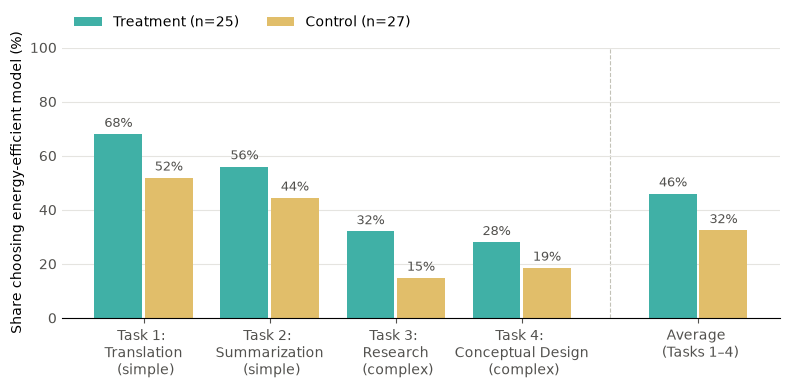

In [4]:
from matplotlib import pyplot as plt

# Share of respondents choosing the MIN model per task, Treatment vs. Control (+ average across tasks)
tasks = ['TASK1', 'TASK2', 'TASK3', 'TASK4']
groups = ['Treatment', 'Control']
colors = {'Treatment': '#40B0A6', 'Control': '#E1BE6A'} 

min_share = (data_analyze[tasks].apply(lambda c: c.str.contains('MIN'))
                .groupby(data_analyze['GROUP2']).mean()
                .reindex(groups) * 100)
min_share['AVG'] = min_share[tasks].mean(axis=1)  # average share across tasks 1-4
cols = tasks + ['AVG']
n_group = data_analyze['GROUP2'].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
width = 0.38
x = np.append(np.arange(len(tasks)), len(tasks) + 0.4)  # extra gap before the average

for j, g in enumerate(groups):
    offset = (j - 0.5) * (width + 0.02)  # small gap between the paired bars
    bars = ax.bar(x + offset, min_share.loc[g, cols], width=width, color=colors[g], zorder=2,
                  label=f'{g} (n={n_group[g]})')
    for bar, pct in zip(bars, min_share.loc[g, cols]):
        ax.annotate(f'{pct:.0f}%', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom',
                    fontsize=9, color='#52514e')

# Divider between the individual tasks and the average
ax.axvline((x[-2] + x[-1]) / 2, color='#c3c2b7', linewidth=0.8, linestyle='--', zorder=1)

task_labels = {
    'TASK1': 'Task 1: \n Translation \n (simple)',
    'TASK2': 'Task 2: \n Summarization \n (simple)',
    'TASK3': 'Task 3: \n Research \n (complex)',
    'TASK4': 'Task 4: \n Conceptual Design \n (complex)',
    'AVG': 'Average \n (Tasks 1–4)',
}

ax.set_xticks(x)
ax.set_xticklabels([task_labels[t] for t in cols])
ax.set_ylabel('Share choosing energy-efficient model (%)')
ax.set_ylim(0, 100)
ax.set_title(None)
ax.legend(frameon=False, loc='lower left', bbox_to_anchor=(0, 1.02), ncol=2)  # above the plot, clear of bars and divider

ax.yaxis.grid(True, color='#e5e4e0', linewidth=0.8, zorder=0)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0, colors='#52514e')
ax.tick_params(axis='x', colors='#52514e')

plt.tight_layout()
plt.savefig('shares.svg', format='svg', dpi=600)
plt.savefig('shares.pdf', format='pdf')
plt.show()